In [ ]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


ModuleNotFoundError: No module named 'seaborn'

In [5]:

df = pd.read_csv("../data/interim/listings_parsed_v6.csv")
print(len(df))   # expect 183490

183490


In [8]:
df["is_ward"] = df["municipality"].str.endswith("区").astype(int)
df["region"] = df["municipality"].map(
    lambda x: "ward" if x.endswith("区") else ("city" if x.endswith("市") else "town_village"))

In [9]:
df.to_csv("../data/interim/listings_parsed_v7.csv", index=False)

In [11]:
cols = ["Price_yen", "area_m2", "age_years", "is_new", "floor_min", "stories_above",
        "walk_min_nearest", "municipality", "n_rooms"]
df = pd.read_csv("../data/interim/listings_parsed_v7.csv", usecols=cols)

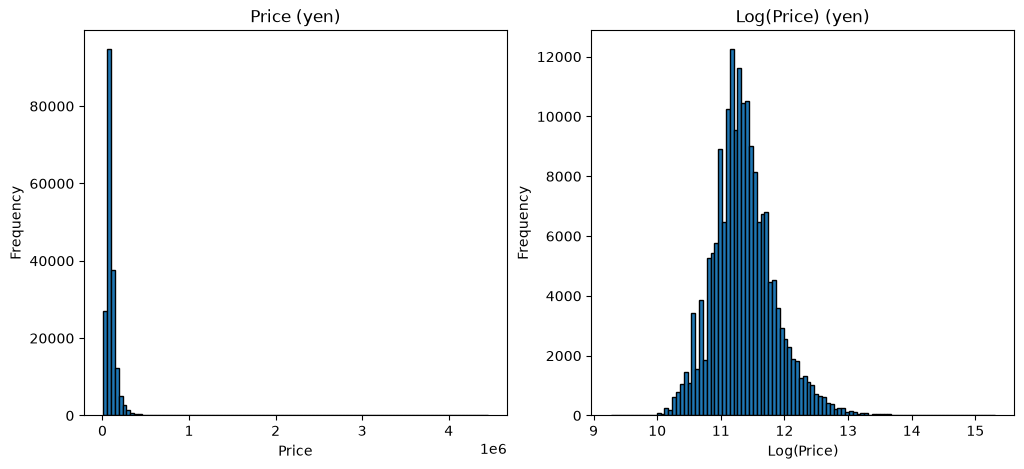

In [15]:
# histogram of price_yen and np.log(price_yen) to see if log transform is needed using matplotlib 
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df["Price_yen"], bins=100, edgecolor='black')
plt.title("Price (yen)")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(np.log(df["Price_yen"]), bins=100, edgecolor='black')
plt.title("Log(Price) (yen)")
plt.xlabel("Log(Price)")
plt.ylabel("Frequency")

plt.show()

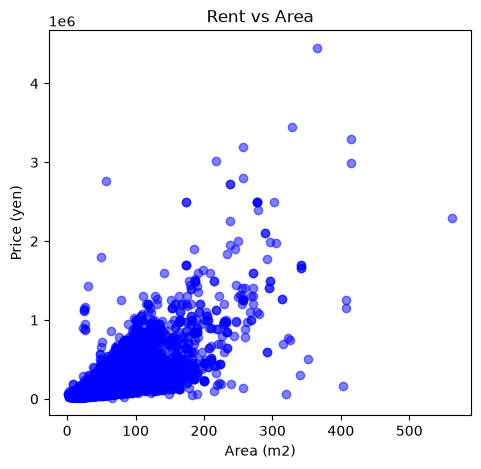

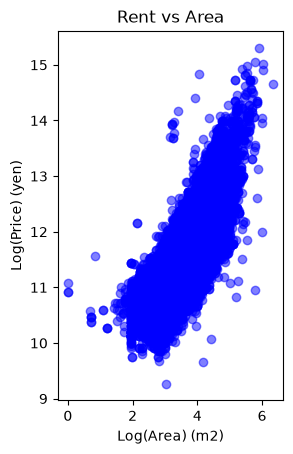

In [16]:
# Rent Vs Area Scatter plot to see if there is a linear relationship between area_m2 and Price_yen, also do log-log comparison, alpha=0.5, color='blue'

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(df["area_m2"], df["Price_yen"], alpha=0.5, color='blue')
plt.xlabel("Area (m2)")
plt.ylabel("Price (yen)")
plt.title("Rent vs Area")
plt.show()

plt.subplot(1, 2, 2)
plt.scatter(np.log(df["area_m2"]), np.log(df["Price_yen"]), alpha=0.5, color='blue')
plt.xlabel("Log(Area) (m2)")
plt.ylabel("Log(Price) (yen)")  
plt.title("Rent vs Area")
plt.show()




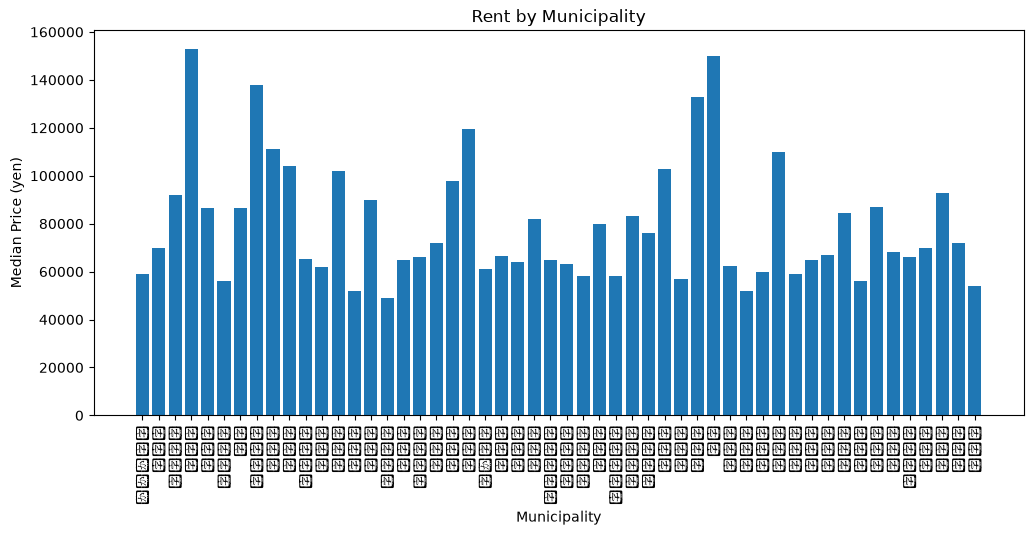

In [19]:
# median rent by municipality
# import missing fonts
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['font.serif'] = ['DejaVu Serif']
plt.figure(figsize=(12, 5))
plt.bar(df.groupby("municipality")["Price_yen"].median().index, df.groupby("municipality")["Price_yen"].median().values)
plt.xticks(rotation=90)
plt.xlabel("Municipality")
plt.ylabel("Median Price (yen)")
plt.title("Rent by Municipality")
plt.show()